In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from pandas.api.types import is_bool_dtype, is_numeric_dtype
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split

sys.path.insert(0, str(Path.cwd().parent))
from ecl.donnees import charger_config, charger_features, moteur

config = charger_config()
GRAINE = config["reproductibilite"]["graine"]
CIBLE = "defaut_observe"

clients = charger_features(moteur(), "train")
clients["duree_mois"] = clients["montant_credit"] / clients["annuite"]
clients["ratio_financement"] = clients["montant_credit"] / clients["prix_bien"]

FEATURES = [c for c in clients.columns if c not in config["variables_exclues"]]
X = clients[FEATURES].copy()
for c in FEATURES:
    if is_bool_dtype(X[c]):
        X[c] = X[c].astype(int)
    elif not is_numeric_dtype(X[c]):
        X[c] = X[c].astype("category")
y = clients[CIBLE]

X_app, X_val, y_app, y_val = train_test_split(
    X, y, test_size=config["reproductibilite"]["part_test"], stratify=y, random_state=GRAINE)

print(f"{len(FEATURES)} variables")
print(f"Apprentissage : {len(X_app)} clients, taux = {y_app.mean():.2%}")
print(f"Validation    : {len(X_val)} clients, taux = {y_val.mean():.2%}")

32 variables
Apprentissage : 21518 clients, taux = 7.94%
Validation    : 9222 clients, taux = 7.94%


In [ ]:
import lightgbm as lgb

params = {
    "objective": "binary", "metric": "auc", "verbosity": -1, "seed": GRAINE,
    "learning_rate": 0.03, "num_leaves": 15, "min_child_samples": 100,
    "feature_fraction": 0.8, "bagging_fraction": 0.8, "bagging_freq": 1, "lambda_l2": 1.0,
}

jeu_app = lgb.Dataset(X_app, y_app)
cv = lgb.cv(params, jeu_app, num_boost_round=3000, nfold=config["reproductibilite"]["nb_plis"],
            stratified=True, seed=GRAINE,
            callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(200)])

nb_arbres = len(cv["valid auc-mean"])
print(f"Nombre d'arbres retenu : {nb_arbres}")
print(f"AUC en validation croisée : {cv['valid auc-mean'][-1]:.4f} (écart-type {cv['valid auc-stdv'][-1]:.4f})")

[200]	valid's auc: 0.754482 + 0.00791705
Nombre d'arbres retenu : 177
AUC en validation croisée : 0.7553 (écart-type 0.0076)


In [ ]:
modele = lgb.train(params, jeu_app, num_boost_round=nb_arbres)

def mesurer(y, p):
    auc = roc_auc_score(y, p)
    fpr, tpr, _ = roc_curve(y, p)
    return {"AUC": auc, "Gini": 2 * auc - 1, "KS": (tpr - fpr).max()}

pd_app = modele.predict(X_app)
pd_val = modele.predict(X_val)

comparaison = pd.DataFrame({
    "scorecard (validation)": {"AUC": 0.7390, "Gini": 0.4781, "KS": 0.3637},   # résultats du lot DS-3
    "challenger (apprentissage)": mesurer(y_app, pd_app),
    "challenger (validation)": mesurer(y_val, pd_val),
})
comparaison["gain du challenger"] = comparaison["challenger (validation)"] - comparaison["scorecard (validation)"]
comparaison.round(4)

,scorecard (validation),challenger (apprentissage),challenger (validation),gain du challenger
AUC,0.7390,0.8329,0.7459,0.0069
Gini,0.4781,0.6658,0.4918,0.0137
KS,0.3637,0.5072,0.3887,0.0250


In [ ]:
import shap

explication = shap.TreeExplainer(modele)(X_val)

# 1. Vérification : base + somme des contributions = prédiction du modèle
brut = modele.predict(X_val, raw_score=True)
reconstruit = explication.base_values + explication.values.sum(axis=1)
print(f"Valeur de base : {explication.base_values[0]:.4f}  (PD = {1 / (1 + np.exp(-explication.base_values[0])):.2%})")
print(f"Écart maximal entre prédiction et reconstruction : {np.abs(brut - reconstruit).max():.8f}")

Valeur de base : -2.7972  (PD = 5.75%)
Écart maximal entre prédiction et reconstruction : 0.00000000


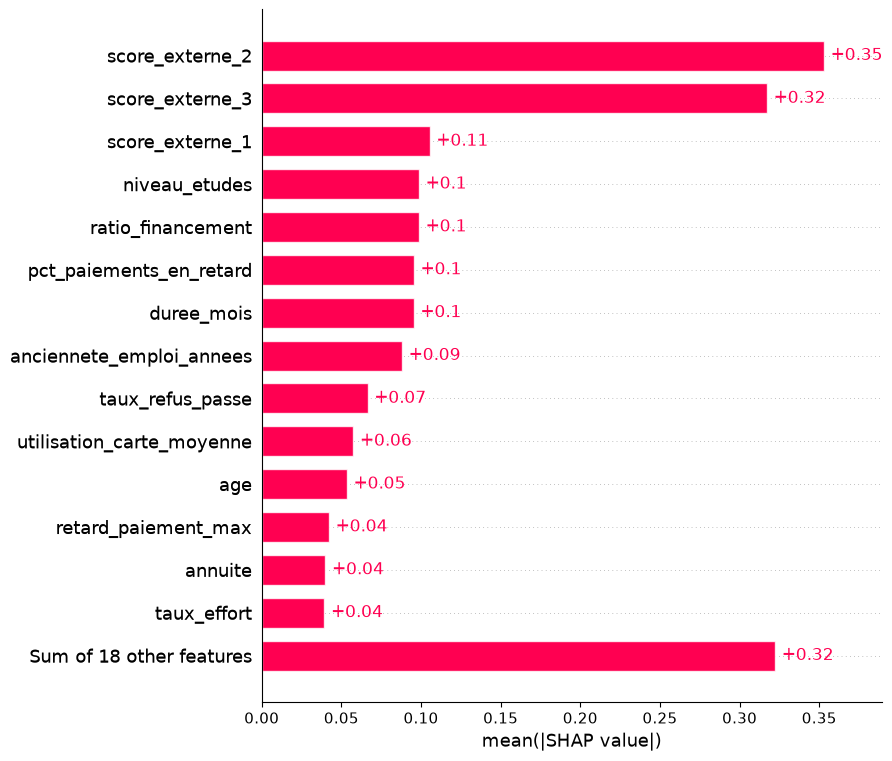

In [ ]:
shap.plots.bar(explication, max_display=15)

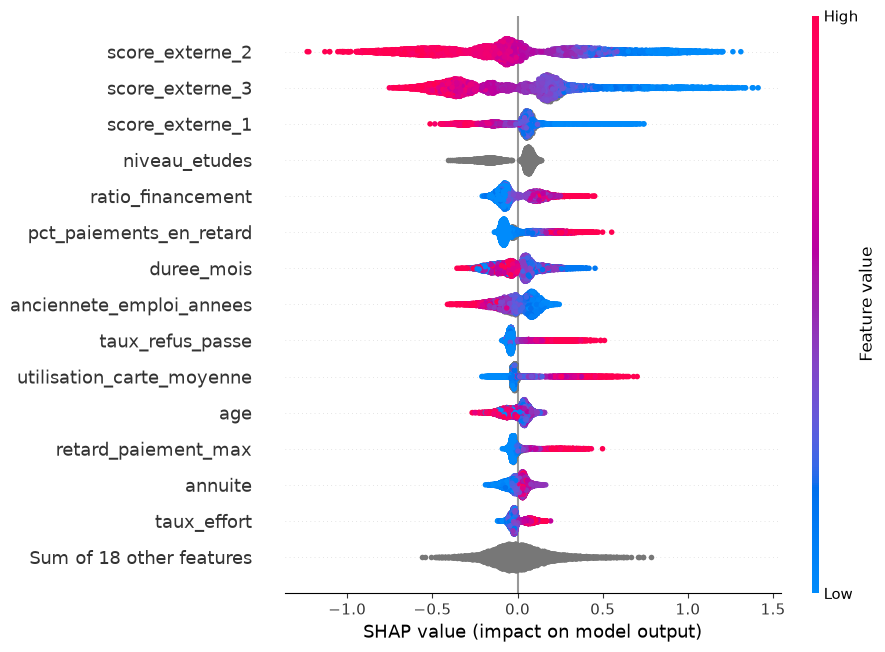

In [ ]:
shap.plots.beeswarm(explication, max_display=15)

Client sûr (5e centile) : PD = 1.86%   (valeur de base : 5.75%)


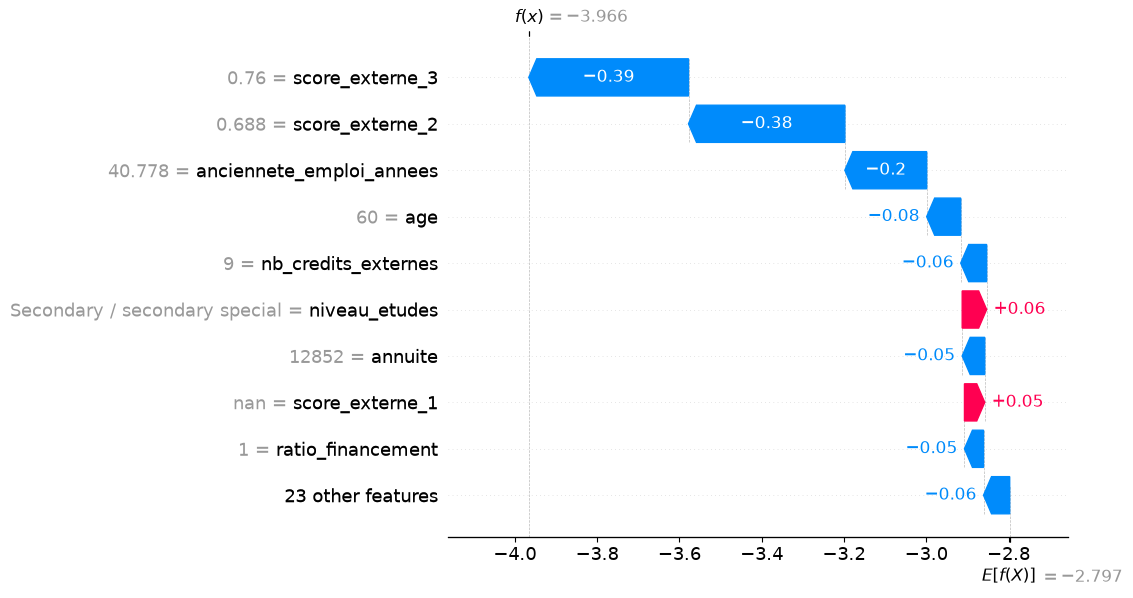

Client moyen (médiane) : PD = 4.89%   (valeur de base : 5.75%)


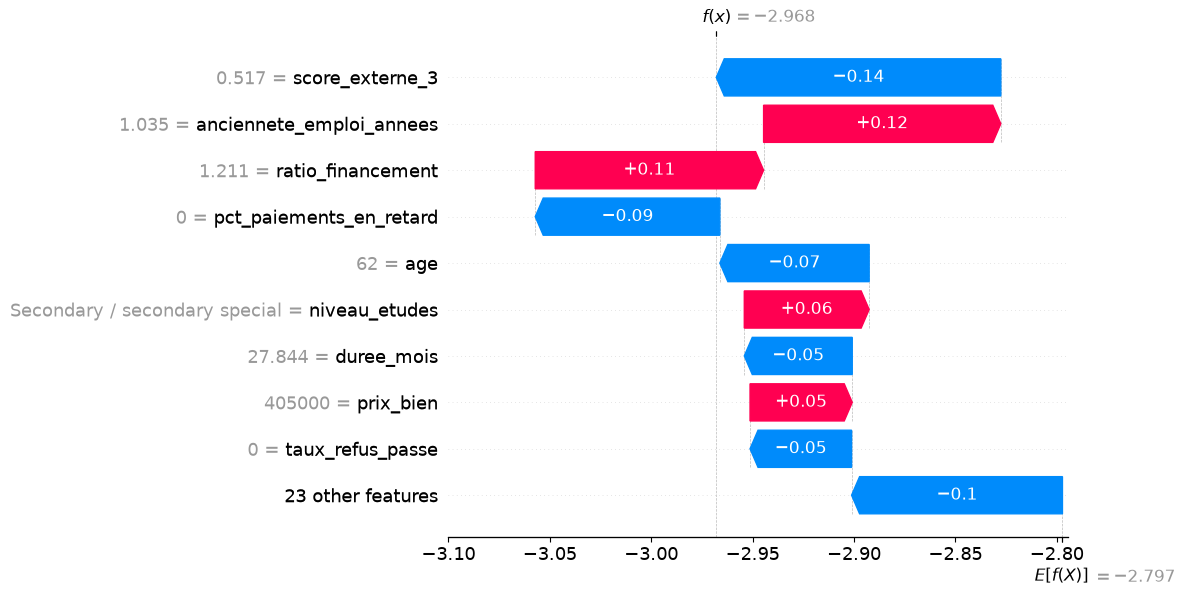

Client risqué (99e centile) : PD = 39.92%   (valeur de base : 5.75%)


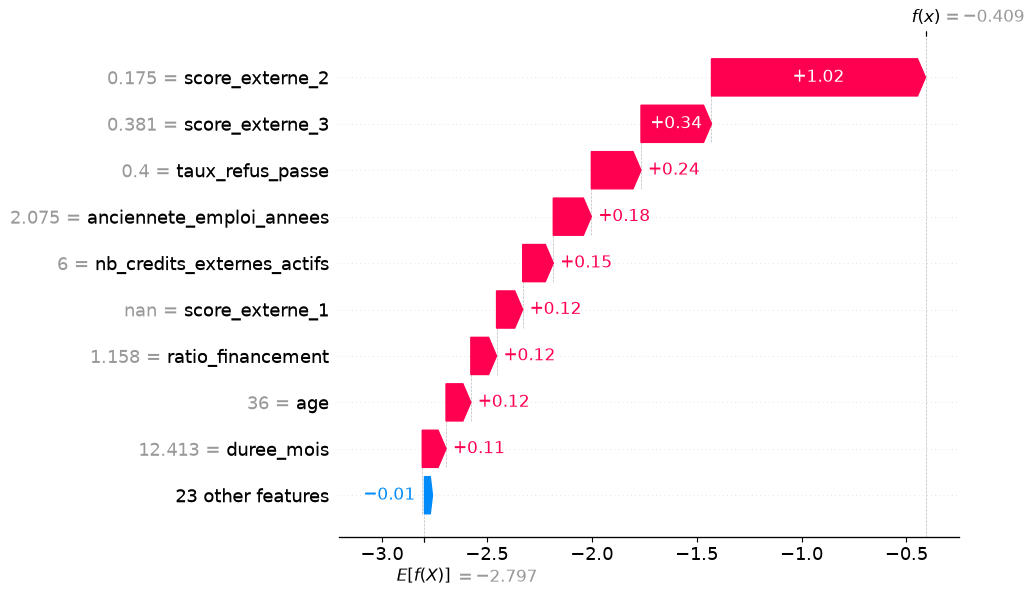

In [ ]:
def pd_de(log_odds):
    return 1 / (1 + np.exp(-log_odds))

ordre = np.argsort(pd_val)
clients_types = {
    "sûr (5e centile)": ordre[int(0.05 * len(ordre))],
    "moyen (médiane)": ordre[int(0.50 * len(ordre))],
    "risqué (99e centile)": ordre[int(0.99 * len(ordre))],
}

for nom, i in clients_types.items():
    print(f"Client {nom} : PD = {pd_val[i]:.2%}   (valeur de base : {pd_de(explication.base_values[i]):.2%})")
    shap.plots.waterfall(explication[i], max_display=10)

In [ ]:
grille = pd.read_csv(Path.cwd().parent.parent / "docs" / "grille_score_v1.csv")
grille[grille["variable"] == "duree_mois"][["classe", "clients", "taux_difficulte", "points"]]

,classe,clients,taux_difficulte,points
23,"(-inf, 10.81)",2293,0.047100,47
24,"[10.81, 20.21)",8602,0.088817,38
25,"[20.21, 21.45)",1767,0.165818,29
26,"[21.45, 31.47)",5641,0.066123,42
27,"[31.47, inf)",3215,0.053188,45


In [ ]:
import json

import matplotlib.pyplot as plt
import mlflow
import mlflow.lightgbm

DS = Path.cwd().parent
mlflow.set_tracking_uri(f"sqlite:///{(DS / 'mlflow.db').as_posix()}")
if mlflow.get_experiment_by_name("pd_challenger") is None:
    mlflow.create_experiment("pd_challenger", artifact_location=(DS / "mlruns").as_uri())
mlflow.set_experiment("pd_challenger")

dossier = DS / "artefacts_tmp" / "challenger"
dossier.mkdir(parents=True, exist_ok=True)
shap.plots.bar(explication, max_display=15, show=False)
plt.savefig(dossier / "shap_importance.png", dpi=120, bbox_inches="tight")
plt.close()
shap.plots.beeswarm(explication, max_display=15, show=False)
plt.savefig(dossier / "shap_nuage.png", dpi=120, bbox_inches="tight")
plt.close()
comparaison.round(4).to_csv(dossier / "comparaison_scorecard.csv")

with mlflow.start_run(run_name="challenger_lightgbm_v1"):
    mlflow.log_params({**{k: v for k, v in params.items() if k != "verbosity"},
                       "nb_arbres": nb_arbres, "nb_variables": len(FEATURES)})
    mlflow.log_metrics({
        "auc_apprentissage": comparaison.loc["AUC", "challenger (apprentissage)"],
        "auc_validation": comparaison.loc["AUC", "challenger (validation)"],
        "gini_validation": comparaison.loc["Gini", "challenger (validation)"],
        "ks_validation": comparaison.loc["KS", "challenger (validation)"],
        "auc_cv_moyenne": cv["valid auc-mean"][-1],
        "auc_cv_ecart_type": cv["valid auc-stdv"][-1],
        "gain_auc_vs_scorecard": comparaison.loc["AUC", "gain du challenger"],
    })
    mlflow.lightgbm.log_model(modele, name="modele")
    mlflow.log_artifacts(str(dossier))
    print("Run enregistrée :", mlflow.active_run().info.run_id)

Run enregistrée : 5ed9fcae1a884d5f81a0807efd91d79a
